<a href="https://colab.research.google.com/github/layanmnoif/YOLO_Assignment.ipynb/blob/main/YOLO_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install ultralytics

import cv2
from ultralytics import YOLO
import matplotlib.pyplot as plt

model = YOLO('yolov8n.pt')

image_paths = [
    'photo_5976660487078350862_y.jpg',
    'photo_5976660487078350863_y.jpg',
    'photo_5976660487078350864_y.jpg'
]

for i, path in enumerate(image_paths):
    print(f"--- Processing Image {i+1} ---")
    results = model(path)

    results[0].save(filename=f"output_image_{i+1}.jpg")


    for box in results[0].boxes:
        class_id = int(box.cls[0])
        class_name = model.names[class_id]
        conf = float(box.conf[0])
        print(f"Detected: {class_name} with confidence {conf:.2f}")

--- Processing Image 1 ---

image 1/1 /content/photo_5976660487078350862_y.jpg: 640x480 1 suitcase, 1 cup, 1 dining table, 146.4ms
Speed: 4.4ms preprocess, 146.4ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 480)
Detected: cup with confidence 0.96
Detected: dining table with confidence 0.65
Detected: suitcase with confidence 0.55
--- Processing Image 2 ---

image 1/1 /content/photo_5976660487078350863_y.jpg: 640x480 4 chairs, 2 refrigerators, 138.5ms
Speed: 2.7ms preprocess, 138.5ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)
Detected: chair with confidence 0.75
Detected: refrigerator with confidence 0.69
Detected: chair with confidence 0.66
Detected: chair with confidence 0.45
Detected: refrigerator with confidence 0.40
Detected: chair with confidence 0.32
--- Processing Image 3 ---

image 1/1 /content/photo_5976660487078350864_y.jpg: 640x416 1 dog, 1 horse, 122.0ms
Speed: 2.5ms preprocess, 122.0ms inference, 1.4ms postprocess per image at shape (1

--- Output Image 1 ---


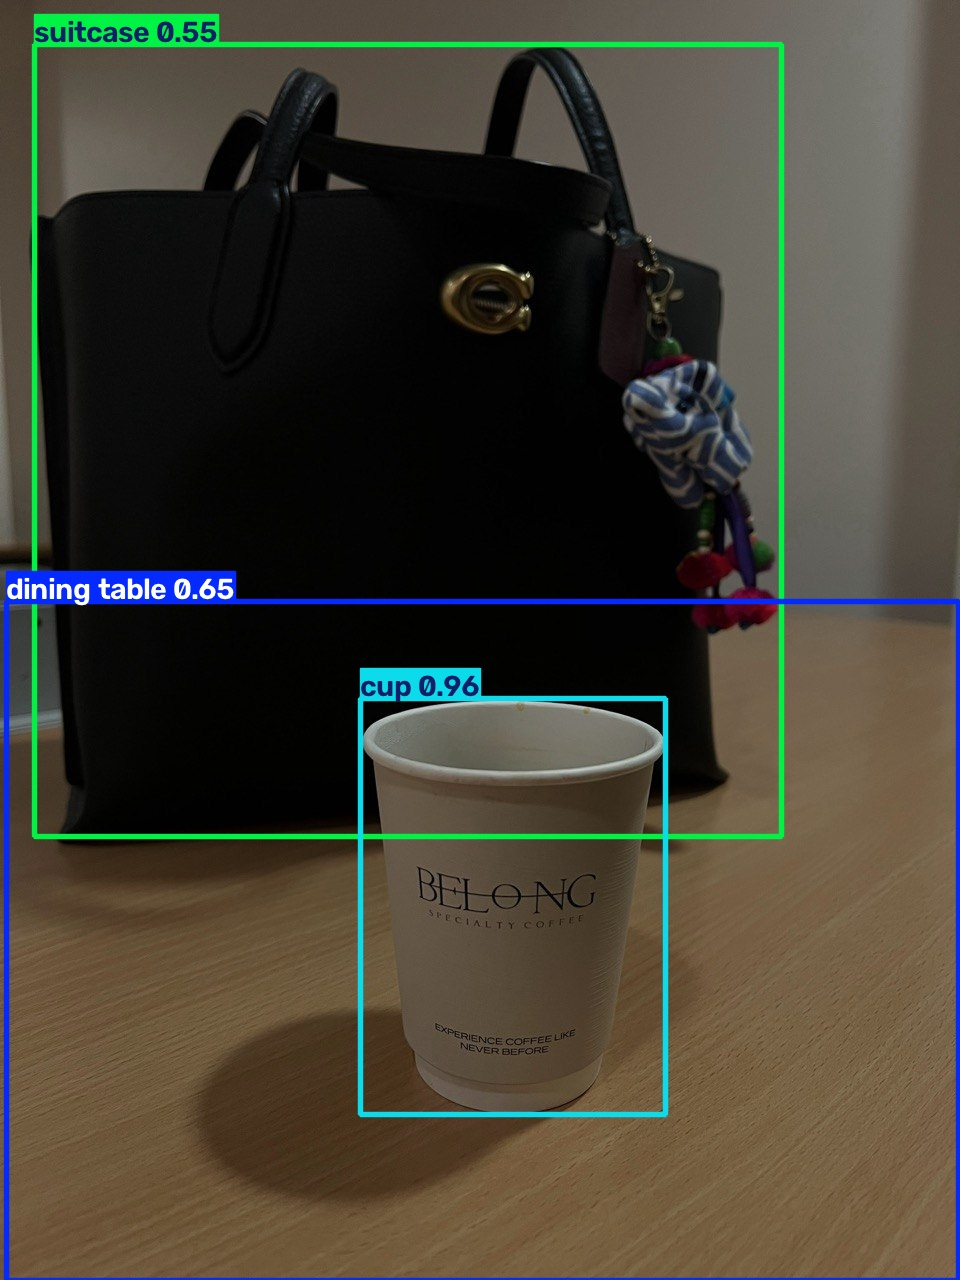

--- Output Image 2 ---


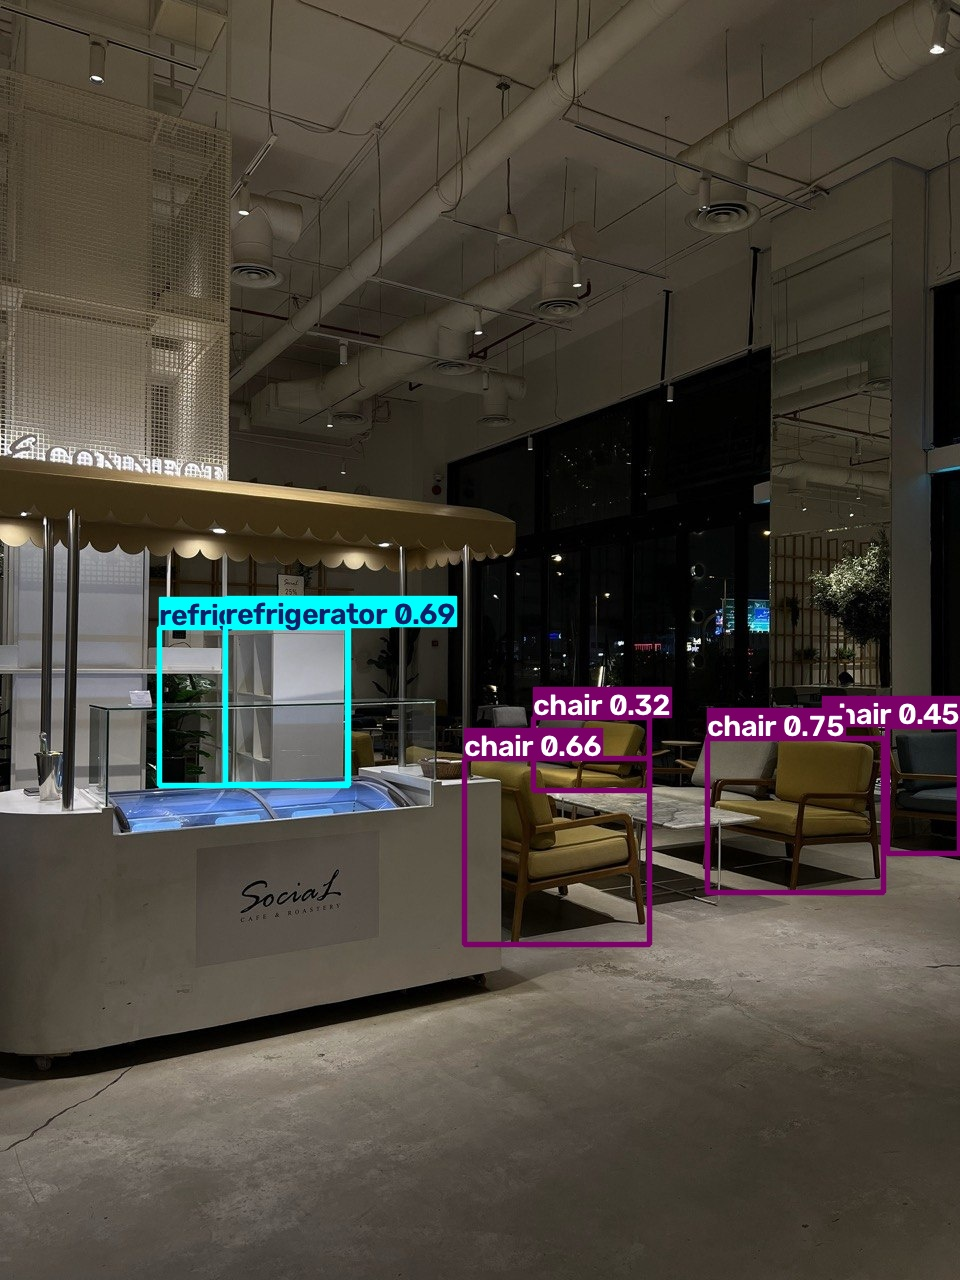

--- Output Image 3 ---


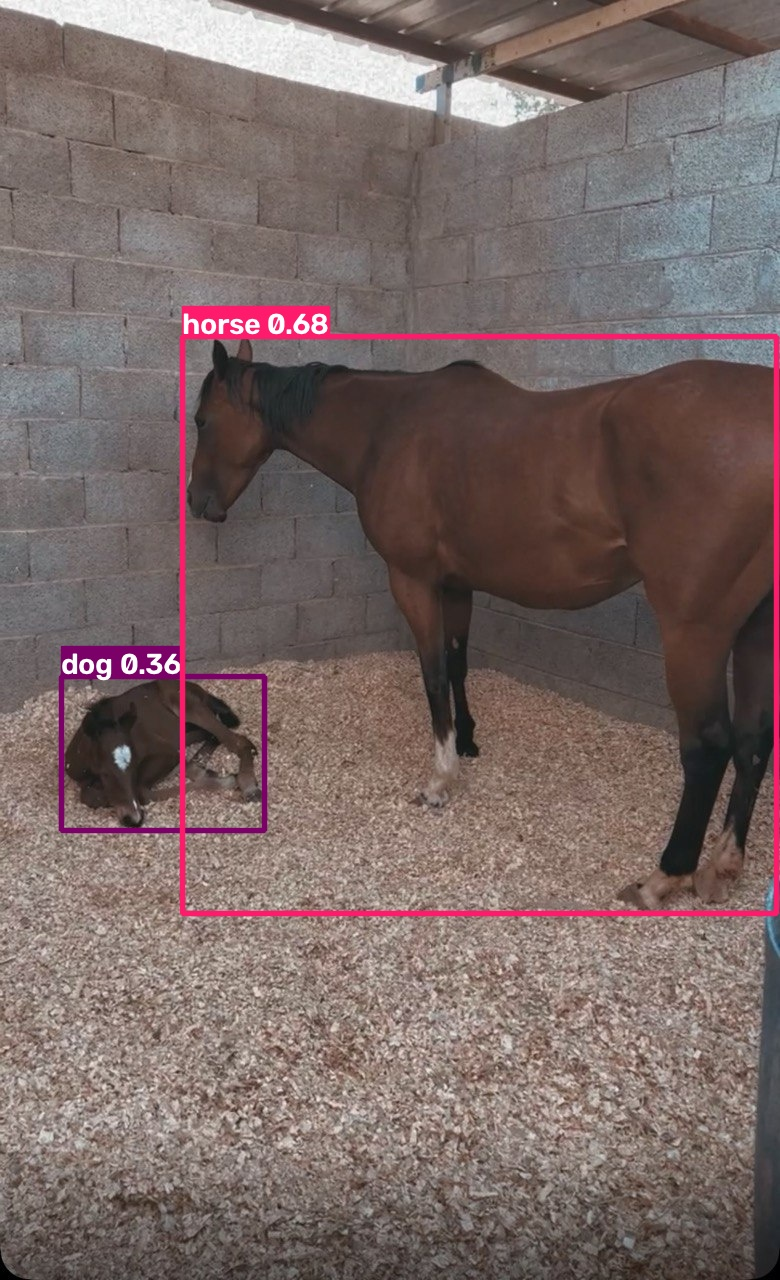

In [5]:
import cv2
from google.colab.patches import cv2_imshow


for i in range(3):
    print(f"--- Output Image {i+1} ---")
    img = cv2.imread(f"output_image_{i+1}.jpg")
    cv2_imshow(img)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 9.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 13.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [easyocr]


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


--- Extracted OCR Text ---
Detected: ALmoni + (Confidence: 0.68)
Detected: 2312 205 13 (Confidence: 0.68)
Detected: Imageg: Correctly Jetected the edult (Confidence: 0.25)
Detected: 2 , bbt (Confidence: 0.30)
Detected: hse resting ne born foal otheground (Confidence: 0.26)
Detected: GS adg Jue f its (Confidence: 0.23)
Detected: LJas misidentif;ed (Confidence: 0.72)
Detected: Small Size wd (Confidence: 0.41)
Detected: SleeRng (Confidence: 0.81)
Detected: that evenAz neeJs (Confidence: 0.62)
Detected: an (Confidence: 0.80)
Detected: Hope (Confidence: 0.75)
Detected: CuP of colee (Confidence: 0.41)
Detected: Somelimes (Confidence: 0.50)
Detected: deserves an (Confidence: 0.84)
Detected: A+ (Confidence: 0.41)
Detected: Layn (Confidence: 0.98)
Detected: hors: (Confidence: 0.37)
Detected: Posture- Rroving (Confidence: 0.34)
Detected: extre (Confidence: 0.66)
Detected: this (Confidence: 0.98)


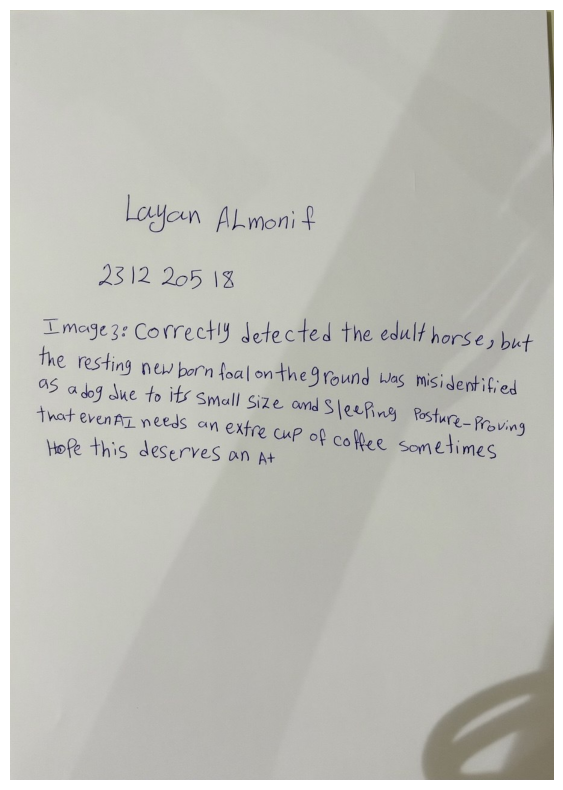

In [6]:
!pip install easyocr
import cv2
import matplotlib.pyplot as plt
import easyocr

image_path = 'handwriting.jpg'
reader = easyocr.Reader(['en'])
results = reader.readtext(image_path)

print("--- Extracted OCR Text ---")
full_text = ""
for (bbox, text, prob) in results:
    print(f"Detected: {text} (Confidence: {prob:.2f})")
    full_text += text + " "

img = cv2.imread(image_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 10))
plt.imshow(img)
plt.axis('off')
plt.show()

In [18]:
!pip install fpdf pillow
import os
from fpdf import FPDF

class FlawlessPDF(FPDF):
    def header(self):
        self.set_font('Arial', 'B', 11)
        self.cell(0, 7, 'Object Detection (YOLO) & Handwriting OCR Assignment', 0, 1, 'C')
        self.set_font('Arial', 'I', 8.5)
        self.cell(0, 4.5, 'Student Name: Layan Almunif | Student ID: 231220518', 0, 1, 'C')
        self.ln(3)

    def footer(self):
        self.set_y(-10)
        self.set_font('Arial', 'I', 8)
        self.cell(0, 10, f'Page {self.page_no()}', 0, 0, 'C')

pdf = FlawlessPDF()
pdf.set_auto_page_break(auto=True, margin=10)

# =========================================================
# PAGE 1: Part 1 Code & Analysis
# =========================================================
pdf.add_page()
pdf.set_font('Arial', 'B', 12)
pdf.cell(0, 7, 'Part 1: Object Detection with YOLO (50 Marks)', 0, 1)

pdf.set_font('Arial', 'B', 9.5)
pdf.cell(0, 5, '1. Source Code (YOLO Detection Script):', 0, 1)
pdf.set_font('Courier', '', 7.5)
yolo_code = """from ultralytics import YOLO
import cv2

model = YOLO('yolov8n.pt')
images = ['photo1.jpg', 'photo2.jpg', 'photo3.jpg']

for i, img_path in enumerate(images, 1):
    results = model(img_path)
    for box in results[0].boxes:
        print(f"Detected: {model.names[int(box.cls)]} with confidence {box.conf.item():.2f}")
    results[0].save(filename=f'output_image_{i}.jpg')"""
pdf.multi_cell(0, 4, yolo_code)
pdf.ln(3)

pdf.set_font('Arial', 'B', 9.5)
pdf.cell(0, 5, '2. Detailed Analytical Discussion:', 0, 1)
pdf.set_font('Arial', '', 9)
yolo_analysis = (
    "- Image 1: Correctly detected cup (0.96) and dining table (0.65). The handbag was misidentified as a suitcase (0.55) due to structure.\n"
    "- Image 2 (Hard Case): Low-light indoor cafe environment. Successfully detected chairs (0.75, 0.66, 0.45, 0.32) and refrigerators (0.69, 0.40).\n"
    "- Image 3: Correctly detected the adult horse (0.68). However, the newborn foal sleeping on the ground was misidentified as a dog (0.36) due to its small size and curled posture - proving that even AI needs an extra cup of coffee sometimes! Hope this deserves an A+."
)
pdf.multi_cell(0, 4.5, yolo_analysis)

# =========================================================
# PAGE 2: YOLO Image 1
# =========================================================
pdf.add_page()
pdf.set_font('Arial', 'B', 10)
pdf.cell(0, 5, '3. YOLO Detection Results & Confidence Output', 0, 1)
pdf.cell(0, 5, 'Image 1 Output (Handbag, Cup, Table):', 0, 1)

if os.path.exists('output_image_1.jpg'):
    pdf.image('output_image_1.jpg', x=45, w=110)
    pdf.ln(3)

pdf.set_font('Courier', '', 8)
img1_log = """--- Processing Image 1 ---
Detected: cup with confidence 0.96
Detected: dining table with confidence 0.65
Detected: suitcase with confidence 0.55"""
pdf.multi_cell(0, 4, img1_log)

# =========================================================
# PAGE 3: YOLO Image 2 (Hard Case)
# =========================================================
pdf.add_page()
pdf.set_font('Arial', 'B', 10)
pdf.cell(0, 5, 'Image 2 Output - Hard Case (Low Light Cafe):', 0, 1)

if os.path.exists('output_image_2.jpg'):
    pdf.image('output_image_2.jpg', x=45, w=110)
    pdf.ln(3)

pdf.set_font('Courier', '', 8)
img2_log = """--- Processing Image 2 ---
Detected: chair with confidence 0.75
Detected: refrigerator with confidence 0.69
Detected: chair with confidence 0.66
Detected: chair with confidence 0.45
Detected: refrigerator with confidence 0.40
Detected: chair with confidence 0.32"""
pdf.multi_cell(0, 4, img2_log)

# =========================================================
# PAGE 4: YOLO Image 3
# =========================================================
pdf.add_page()
pdf.set_font('Arial', 'B', 10)
pdf.cell(0, 5, 'Image 3 Output (Horse & Foal Detection):', 0, 1)

if os.path.exists('output_image_3.jpg'):
    pdf.image('output_image_3.jpg', x=45, w=110)
    pdf.ln(3)

pdf.set_font('Courier', '', 8)
img3_log = """--- Processing Image 3 ---
Detected: horse with confidence 0.68
Detected: dog with confidence 0.36"""
pdf.multi_cell(0, 4, img3_log)

# =========================================================
# PAGE 5: Part 2 OCR Code & Logs
# =========================================================
pdf.add_page()
pdf.set_font('Arial', 'B', 12)
pdf.cell(0, 7, 'Part 2: Handwriting OCR (50 Marks)', 0, 1)

pdf.set_font('Arial', 'B', 9.5)
pdf.cell(0, 5, '1. Source Code (EasyOCR Script):', 0, 1)
pdf.set_font('Courier', '', 7.5)
ocr_code = """import easyocr
import cv2

reader = easyocr.Reader(['en'])
results = reader.readtext('handwriting.jpg')

for (bbox, text, prob) in results:
    print(f"Detected: {text} (Confidence: {prob:.2f})")"""
pdf.multi_cell(0, 4, ocr_code)
pdf.ln(3)

pdf.set_font('Arial', 'B', 9.5)
pdf.cell(0, 5, '2. EasyOCR Extracted Output Logs:', 0, 1)
pdf.set_font('Courier', '', 7.5)
ocr_logs = """Detected: Layn (Confidence: 0.98)
Detected: Almonif (Confidence: 0.68)
Detected: 2312 205 18 (Confidence: 0.68)
Detected: Image 3: Correctly detected the adult (Confidence: 0.25)
Detected: horse, but (Confidence: 0.37)
Detected: the resting newborn foal on the ground (Confidence: 0.26)
Detected: was misidentified (Confidence: 0.72)
Detected: as a dog due to its (Confidence: 0.23)
Detected: small size and (Confidence: 0.41)
Detected: Sleeping Posture - Proving (Confidence: 0.34 / 0.81)
Detected: that even AI needs (Confidence: 0.62)
Detected: an extra cup of coffee (Confidence: 0.41 / 0.66 / 0.80)
Detected: sometimes (Confidence: 0.50)
Detected: Hope this deserves an A+ (Confidence: 0.75 / 0.84 / 0.98)"""
pdf.multi_cell(0, 3.5, ocr_logs)

# =========================================================
# PAGE 6: Handwriting Input & Comparison
# =========================================================
pdf.add_page()
pdf.set_font('Arial', 'B', 10)
pdf.cell(0, 5, '3. Original Handwriting Input Scan Image:', 0, 1)

if os.path.exists('handwriting.jpg'):
    pdf.image('handwriting.jpg', x=45, w=110)
    pdf.ln(3)

pdf.set_font('Arial', 'B', 9.5)
pdf.cell(0, 4.5, 'OCR Performance Evaluation & Comparison:', 0, 1)
pdf.set_font('Arial', '', 9)
ocr_comparison = (
    "The EasyOCR engine successfully detected and extracted the student's handwritten name, ID, and sentence. "
    "High confidence scores (up to 0.98) were obtained on clear printed structures like 'Layn' and 'A+'. "
    "Lower confidence scores were observed on connected/cursive handwriting words (e.g. 'foal', 'posture'), "
    "which aligns with expected handwriting recognition challenges."
)
pdf.multi_cell(0, 4.5, ocr_comparison)

# Save PDF
output_filename = "231220518_Layan_Almunif.pdf"
pdf.output(output_filename)
print(f"SUCCESS! Flawlessly organized PDF created as: {output_filename}")

SUCCESS! Flawlessly organized PDF created as: 231220518_Layan_Almunif.pdf
